Ian Pope (700717419)  
LSTM vs Transformer Project

Task 1: Load and Prepare the Dataset

In [20]:
#Load in needed libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [21]:
#1 Load the SMS dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [22]:
#2 Display examples and their labels
print("Example SMS Messages:\n")

for i in range(10):
    print("Label:", df['label'].iloc[i], " Message:", df['message'].iloc[i])

Example SMS Messages:

Label: ham  Message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Label: ham  Message: Ok lar... Joking wif u oni...
Label: spam  Message: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Label: ham  Message: U dun say so early hor... U c already then say...
Label: ham  Message: Nah I don't think he goes to usf, he lives around here though
Label: spam  Message: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
Label: ham  Message: Even my brother is not like to speak with me. They treat me like aids patent.
Label: ham  Message: As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune
Label: spa

In [23]:
#3 Show number of spam and ham in dataset
class_counts = df['label'].value_counts()
print("Number of spam and ham in dataset:")
print(class_counts)

Number of spam and ham in dataset:
label
ham     4825
spam     747
Name: count, dtype: int64


In [24]:
#4 Convert labels to integers
df['label'] = df['label'].map({'ham': 0, 'spam': 1})
print(df.head())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


In [25]:
#5 Tokenize the messages and convert into integer sequences
x = df['message'].values
y = df['label'].values

#Set our max vocab_size and create a toeknizer
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(x)
sequences = tokenizer.texts_to_sequences(x)

#Show example
print("Original message:")
print(x[0])
print("Integer sequence:")
print(sequences[0])

Original message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Integer sequence:
[50, 472, 4437, 843, 756, 659, 65, 9, 1328, 89, 124, 352, 1329, 149, 2998, 1330, 68, 59, 4438, 145]


In [26]:
#6 Pad or truncate messages to same length

#Set max sequence length to 50
max_length = 50
padded_sequences = pad_sequences(sequences, maxlen=max_length, padding='post', truncating='post')

print("Padded data shape:", padded_sequences.shape)

Padded data shape: (5572, 50)


In [27]:
#7 Split into train, test, and validation sets
#Split 70% training, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    padded_sequences,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#Split the temp data in half to validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (3900, 50)
Validation shape: (836, 50)
Testing shape: (836, 50)


Task 2: Build a simple LSTM model

In [28]:
#Build the LSTM Model
model = tf.keras.Sequential([

    #Embedding layer
    tf.keras.layers.Embedding(
        input_dim=5000,
        output_dim=64,
        input_length=max_length
    ),

    #LSTM layer with 64 units
    tf.keras.layers.LSTM(64),

    #Dropout layer to prevent overfitting
    tf.keras.layers.Dropout(0.3),

    #Output layer
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [29]:
#Compile and train the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8549 - loss: 0.3903 - val_accuracy: 0.8660 - val_loss: 0.2290
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8597 - loss: 0.2895 - val_accuracy: 0.8660 - val_loss: 0.3527
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8659 - loss: 0.3666 - val_accuracy: 0.8660 - val_loss: 0.3952
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8659 - loss: 0.3858 - val_accuracy: 0.8660 - val_loss: 0.3365
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8659 - loss: 0.3670 - val_accuracy: 0.8660 - val_loss: 0.3341
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8877 - loss: 0.2792 - val_accuracy: 0.9581 - val_loss: 0.1940
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9679 - loss: 0.1538 - val_accuracy: 0.9569 - val_loss: 0.1751
Epoch 8/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9549 - loss: 0.1780 - val_accuracy: 

In [30]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9438 - loss: 0.2006
Test Loss: 0.20061273872852325
Test Accuracy: 0.9437798857688904
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
              precision    recall  f1-score   support

         Ham     0.9643    0.9710    0.9677       724
        Spam     0.8037    0.7679    0.7854       112

    accuracy                         0.9438       836
   macro avg     0.8840    0.8694    0.8765       836
weighted avg     0.9428    0.9438    0.9432       836



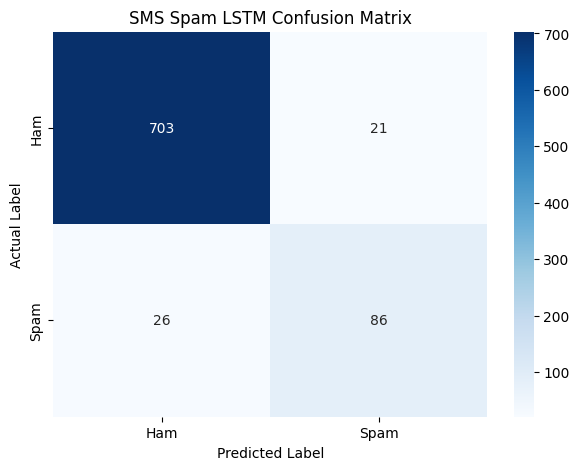

In [31]:
#Get the model loss and accuracy
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:",  test_accuracy)

#Get predictions
y_pred = model.predict(X_test)
y_pred_classes = (y_pred >= 0.5).astype(int).flatten()

#Classification report
print(classification_report(y_test,  y_pred_classes, target_names=['Ham', 'Spam'], digits=4))

#Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("SMS Spam LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


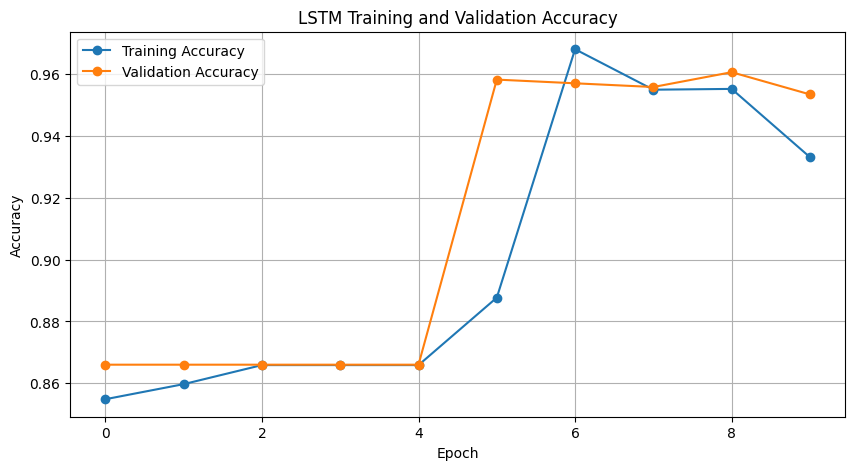

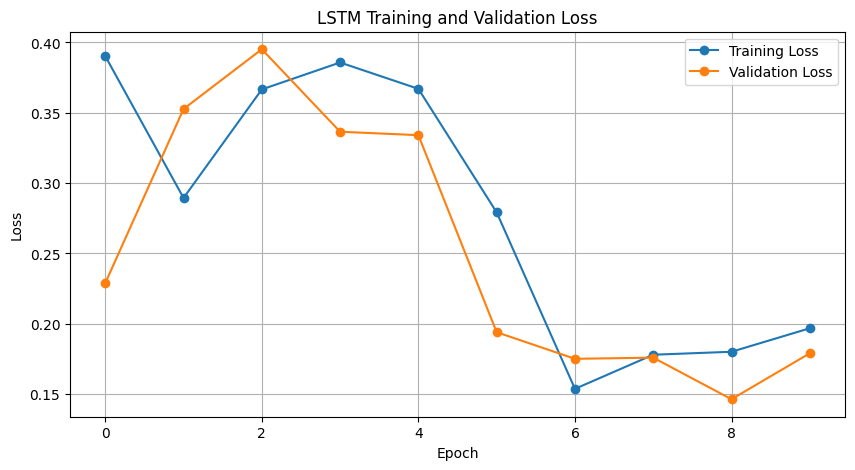

In [33]:
#Plot training/validation loss and accuracy

#Accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

#Loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

Task 3: Build a small transformer model using the same dataset

In [34]:
from tensorflow.keras import layers, Model

In [35]:
#Build the transformer model
#Model parameters
vocab_size = 5000
embed_dim = 32
num_heads = 2
ff_dim = 64

#Input layer
inputs = layers.Input(shape=(max_length,))

#Embedding layer
token_embeddings = layers.Embedding(
    input_dim=vocab_size,
    output_dim=embed_dim,
    mask_zero=True
)(inputs)

#Positional encoding
position_ids = layers.Lambda(
    lambda x: tf.tile(tf.expand_dims(tf.range(max_length), axis=0), [tf.shape(x)[0], 1])
)(inputs)

position_embeddings = layers.Embedding(
    input_dim=max_length,
    output_dim=embed_dim
)(position_ids)

#Combine word and position embeddings
x = layers.Add()([token_embeddings, position_embeddings])

# Create padding attention mask
padding_mask = layers.Lambda(lambda x: tf.not_equal(x, 0), output_shape=(max_length,))(inputs)

attention_mask = layers.Lambda(
    lambda x: tf.logical_and(
        tf.expand_dims(x, axis=1),
        tf.expand_dims(x, axis=2)
    ),
    output_shape=(max_length, max_length)
)(padding_mask)

#Multi-Head Attention
attention_output = layers.MultiHeadAttention(
    num_heads=num_heads,
    key_dim=embed_dim // num_heads,
    dropout=0.3
)(
    query=x,
    value=x,
    key=x,
    attention_mask=attention_mask
)

#Residual connection and normalization
x = layers.Add()([x, attention_output])
x = layers.LayerNormalization(epsilon=1e-6)(x)

#Feed-Forward Network
ffn = layers.Dense(ff_dim, activation='relu')(x)
ffn = layers.Dense(embed_dim)(ffn)

#Residual connection and normalization
x = layers.Add()([x, ffn])
x = layers.LayerNormalization(epsilon=1e-6)(x)

#Dropout
x = layers.Dropout(0.3)(x)

#Pooling Layer
x = layers.Lambda(
    lambda tensors: tf.reduce_sum(
        tensors[0] * tf.cast(
            tf.expand_dims(tensors[1], axis=-1),
            tf.float32
        ),
        axis=1
    ) / tf.maximum(
        tf.reduce_sum(
            tf.cast(tensors[1], tf.float32),
            axis=1,
            keepdims=True
        ),
        1.0
    ),
    output_shape=(embed_dim,)
)([x, padding_mask])

#Output layer
outputs = layers.Dense(1, activation='sigmoid')(x)

# Create model
transformer_model = Model(inputs=inputs, outputs=outputs)

transformer_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_4 (Lambda)   │ (None, 50)        │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 50, 32)    │    160,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 50, 32)    │      1,600 │ lambda_4[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_5 (Lambda)   │ (None, 50)        │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 50, 32)    │          0 │ embedding_4[0][0… │
│                     │                   │            │ embedding_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_6 (Lambda)   │ (None, 50, 50)    │          0 │ lambda_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 50, 32)    │      4,224 │ lambda_6[0][0],   │
│ (MultiHeadAttentio… │                   │            │ add_3[0][0],      │
│                     │                   │            │ add_3[0][0],      │
│                     │                   │            │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 50, 32)    │          0 │ add_3[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 50, 32)    │         64 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 50, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 50, 32)    │      2,080 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 50, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 50, 32)    │         64 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 50, 32)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_7 (Lambda)   │ (None, 32)        │          0 │ dropout_5[0][0],  │
│                     │                   │            │ lambda_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         33 │ lambda_7[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 170,177 (664.75 KB)

 Trainable params: 170,177 (664.75 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
#Compile the model
transformer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [39]:
#Train the model
transformer_history = transformer_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 1.0000 - loss: 2.1564e-04 - val_accuracy: 0.9904 - val_loss: 0.0572
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 2.1086e-04 - val_accuracy: 0.9904 - val_loss: 0.0585
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 2.0508e-04 - val_accuracy: 0.9904 - val_loss: 0.0593
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.1441e-04 - val_accuracy: 0.9892 - val_loss: 0.0631
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.9993e-04 - val_accuracy: 0.9904 - val_loss: 0.0612
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.9787e-04 - val_accuracy: 0.9904 - val_loss: 0.0622
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 1.9812e-04 - val_accuracy: 0.9892 - val_loss: 0.0632
Epoch 8/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - los

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9892 - loss: 0.0940
Test Loss: 0.09400581568479538
Test Accuracy: 0.989234447479248
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step
              precision    recall  f1-score   support

         Ham     0.9904    0.9972    0.9938       724
        Spam     0.9813    0.9375    0.9589       112

    accuracy                         0.9892       836
   macro avg     0.9859    0.9674    0.9764       836
weighted avg     0.9892    0.9892    0.9891       836



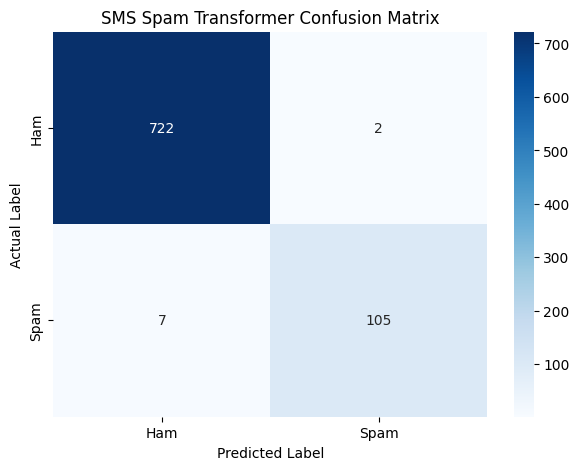

In [40]:
#Get the transformer loss and accuracy
transformer_test_loss, transformer_test_accuracy = transformer_model.evaluate(X_test, y_test, verbose=1)

print("Test Loss:", transformer_test_loss)
print("Test Accuracy:",  transformer_test_accuracy)

#Get predictions
y_pred = transformer_model.predict(X_test)
y_pred_classes = (y_pred >= 0.5).astype(int).flatten()

#Classification report
print(classification_report(y_test,  y_pred_classes, target_names=['Ham', 'Spam'], digits=4))

#Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("SMS Spam Transformer Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


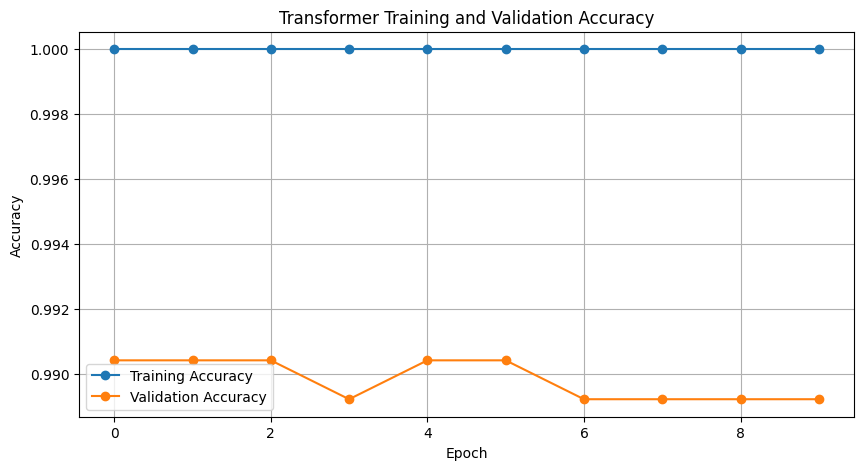

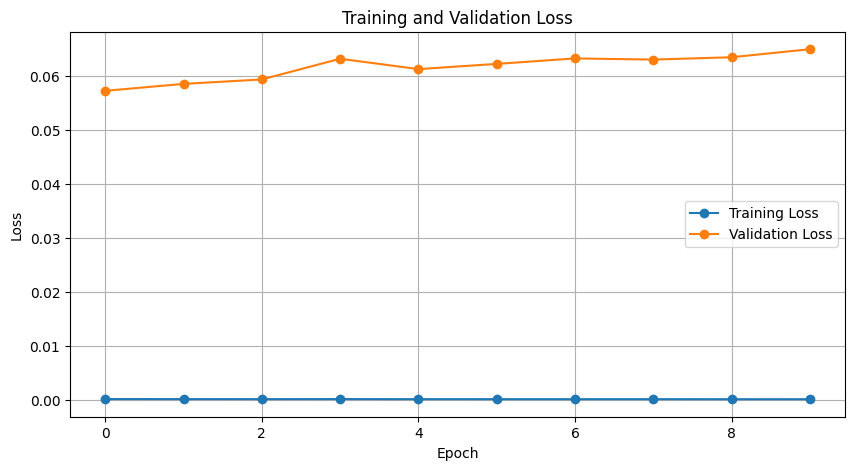

In [41]:
#Plot transformer training/validation loss and accuracy

#Accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    transformer_history.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    transformer_history.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title("Transformer Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

#Loss
plt.figure(figsize=(10, 5))

plt.plot(
    transformer_history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    transformer_history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

Model       | Accuracy | Precision | Recall | F1-Score | Training Time   
LSTM        | 0.9438   | 0.8037    | 0.7679 | 0.7854   | 15s  
Transformer | 0.9892   | 0.9813    | 0.9375 | 0.9589   | 6s

Experiment Overview -
The transformer model achieved much better results on the test data than the LSTM model, specifically doing much better on the target class of spam messages. It contained significantly higher f1-score for that class than the LSTM. The transformer model also trained much faster in 5 seconds as compared to the 15 seconds for the LSTM model. Despite the very good performance, the transformer model was overfitting to the dataset, as the validation loss was actually lowest after the first epoch. Due to the best performance of the LSTM model coming in the second to last epoch, it is hard to tell if the model suffered from overfitting, but I would say that it did not. The differences in the model performances as well as training time can likely be attributed to the differences in how the models work. The main difference between techniques is that the transformer uses an attention mechanism. This means the transformer is able to train in parrallel for lower training times by masking data and is also able to provide context to words using information that comes from later words in a sentence which can lead to better performance. Neither of these are possible for the LSTM which must train and process data sequentially. I would personally use the transformer model for looking for spam messages, as the training times and performance are both significantly better. As the training datasets grow in size, the distinction in training time will also become more and more important.